# SheSync — reproducible model comparison

Original notebooks and models are preserved. This experiment uses the original historical dataset only; external candidates were excluded after provenance and compatibility checks. See `../research/DATASET_REPORT.md`.

SMOTE is fitted only in training folds. Hyperparameter selection uses training CV F1. The test set is reserved until model selection has completed. Reported baseline figures and new experiments are separate.

In [ ]:
from pathlib import Path
import json
import pandas as pd
root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
results = json.loads((root / "experiments/results.json").read_text())
metrics = pd.DataFrame([{ "model": r["name"], **r["test"] } for r in results["results"]])
metrics


# Measured model experiments

Seven model families were trained on the original historical 541-record dataset. No external cohort was added. Original models and notebook remain unchanged.

Stratified held-out split: 432 training / 109 test records, seed 137. Identical clinical rows and conflicting duplicate labels are filtered before splitting; none were removed in this file. IDs, target and junk columns are excluded. Median imputation, scaling and SMOTE run only within the training pipeline, including CV folds. Three hyperparameter configurations per model, three stratified CV folds. Model selection uses training CV F1 only, before test evaluation. CV means/std are tuning diagnostics, not an unbiased nested-CV estimate.

| New experiment | Accuracy | Precision | Recall | F1 | ROC-AUC | Brier ↓ |
|---|---|---|---|---|---|---|
| Logistic Regression | 0.881 | 0.811 | 0.833 | 0.822 | 0.934 | 0.082 |
| Support Vector Machine | 0.844 | 0.828 | 0.667 | 0.738 | 0.938 | 0.091 |
| Random Forest | 0.908 | 0.882 | 0.833 | 0.857 | 0.952 | 0.093 |
| XGBoost | 0.908 | 0.882 | 0.833 | 0.857 | 0.958 | 0.077 |
| LightGBM | 0.872 | 0.844 | 0.750 | 0.794 | 0.947 | 0.104 |
| CatBoost | 0.908 | 0.882 | 0.833 | 0.857 | 0.947 | 0.077 |
| Gradient Boosting | 0.881 | 0.871 | 0.750 | 0.806 | 0.954 | 0.084 |

Selected by training CV: **LightGBM**. Its test recall is 0.750, which is lower than the user-reported baseline recall 0.83. It was **not promoted** to clinical inference. Some other experiment models measured 90.8% accuracy, but choosing them after seeing their test scores would make model selection depend on the holdout. Original baseline stays active.

Reported baseline (not independently reproduced as a matched split here): accuracy 0.834, precision 0.84, recall 0.83, F1 0.727, AUC 0.91. Different splits and preprocessing mean these values cannot establish a statistically demonstrated improvement over the paper. The preserved original notebook fits median imputation before its split and does not stratify its split; new experiment avoids those issues. SMOTE in the original notebook occurs after splitting.

Results JSON includes parameters, package versions, source SHA-256, CV mean/std, confusion matrices, ROC points, Brier scores, and 500-replicate stratified bootstrap 95% intervals. Intervals are conditional on one small cohort/split; there is no external clinical validation or individual risk calibration. Class imbalance is 364 negative / 177 positive. No patient records were fabricated; only fold-local training resampling uses synthetic points.

Experimental pipelines are saved under experiments/*.joblib. Original saved RF and XGBoost remain in models/. They cannot be honestly benchmarked on the new holdout as if unseen: some of those records were in their original training split.

Run:
```powershell
python training/benchmark.py
```
Use the versions recorded in results.json to reproduce the measured experiment. Do not repeatedly search random split seeds for better accuracy. Every subsequent protocol change must be documented and independently validated before promotion.

SHAP importance for the CV-selected LightGBM is measured on held-out records after its training-fitted preprocessing. Baseline website SHAP comes directly from the original XGBoost using complete exact-schema clinical inputs.


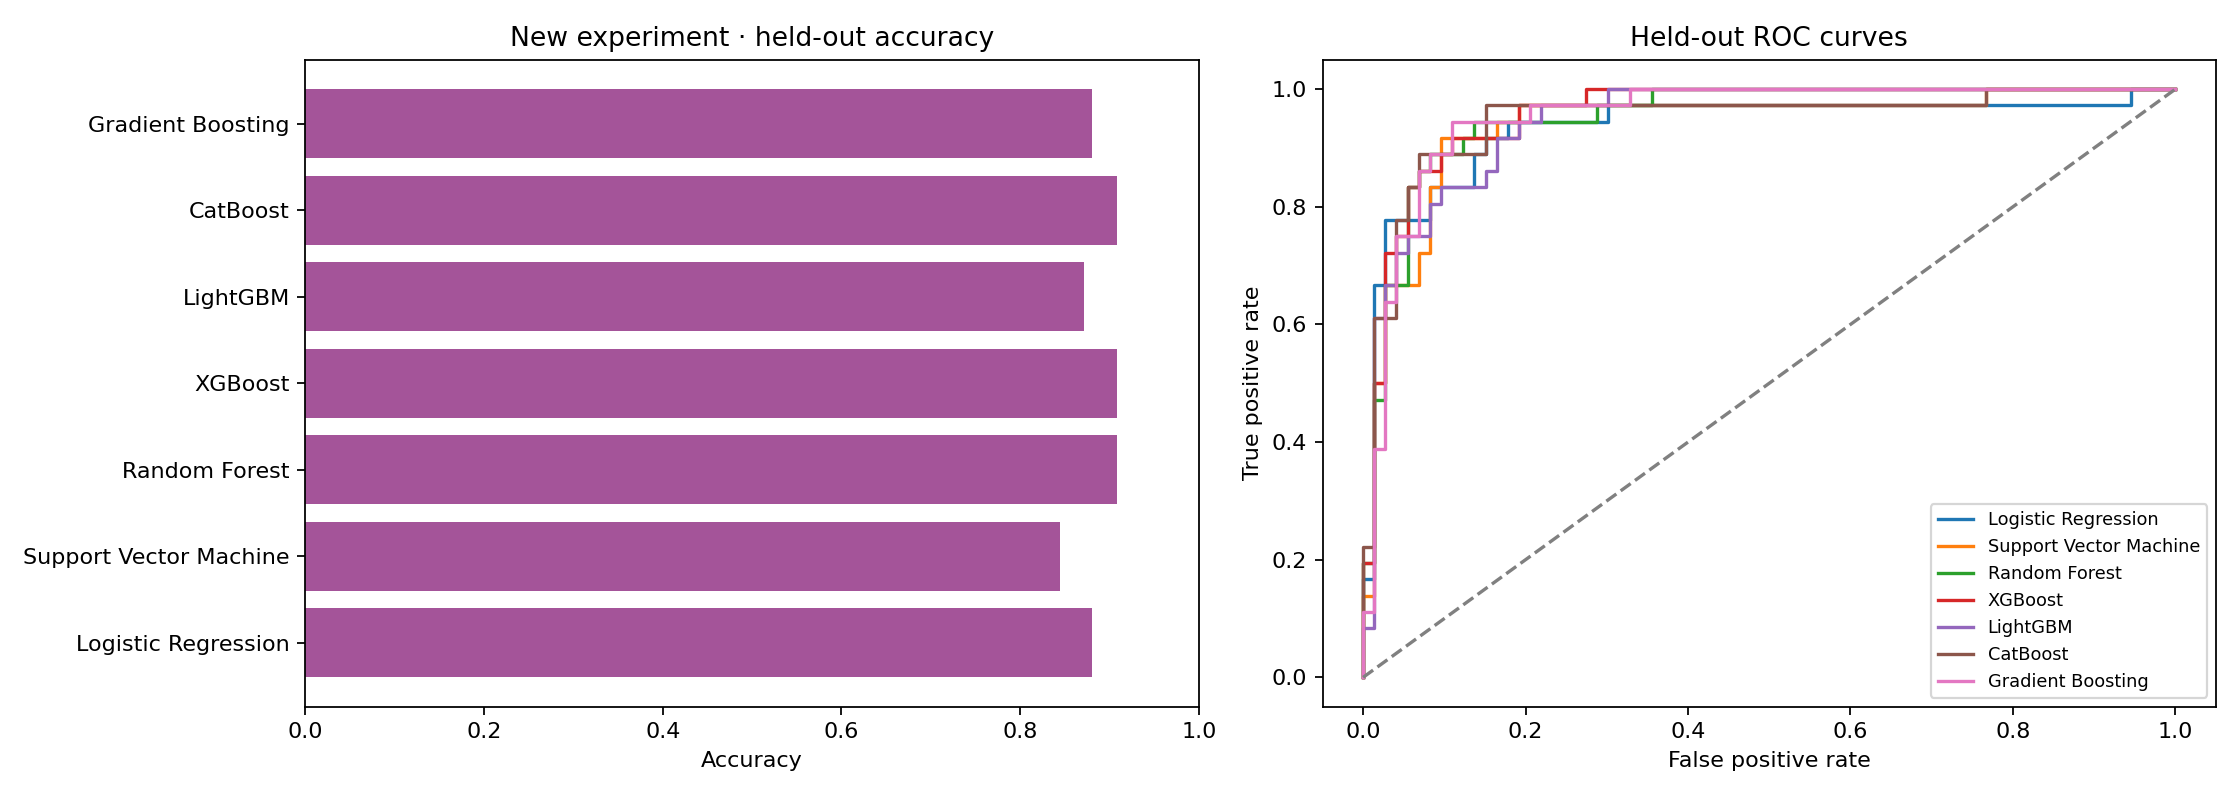

In [ ]:
from IPython.display import Image, display
display(Image(filename=str(root / "experiments/comparison.png")))


## Re-run the documented protocol

The next cell retrains all seven models. Original artifacts are not overwritten. Keep the seed and split protocol fixed; do not choose models based on holdout scores. Use a fresh independently collected cohort for promotion validation.

In [ ]:
import runpy
runpy.run_path(str(root / "training/benchmark.py"), run_name="__main__")


## Interpretation

LightGBM was selected by training CV. Its held-out recall was 0.750, so there is no justified promotion over the reported baseline. Uncalibrated model probabilities are research outputs, not confirmed individual clinical risks. Candidate dataset audits and raw metadata are saved under `research/`.